In [1]:
import numpy as np
import energyflow as ef
import fastjet as fj
import matplotlib.pyplot as plt

dataset_length = 4000
num_dataset = 8
num_particles = 150
num_attr = 4

data_path = "../medium_dataset/"
file_names = [
    "QCD_4k.npz",
    "HToBB_4k.npz",
    "HToCC_4k.npz",
    "HToGG_4k.npz",
    "HToWW4Q_4k.npz",
    "ZToQQ_4k.npz",
    "WToQQ_4k.npz",
    "TTBar_4k.npz",
]

all_events = np.zeros((num_dataset * dataset_length, num_particles, num_attr))
all_labels = np.zeros(num_dataset * dataset_length)

event_blocks = np.zeros((num_dataset, dataset_length, num_particles, num_attr))

for i, file in enumerate(file_names):
    f = np.load(data_path + file)

    x = f["x"]
    y = f["y"]

    all_events[i * dataset_length : (i + 1) * dataset_length] = x
    all_labels[i * dataset_length : (i + 1) * dataset_length] = y

In [2]:
all_events_p4s = ef.p4s_from_ptyphims(all_events)
print(all_events_p4s.shape)
file = open("all_jets_p4s.dat","w")
for i in range(len(all_events_p4s)):
    jet = all_events_p4s[i]
    jet_nozeros = jet[jet[:, 0] > 0]
    for particle in jet_nozeros:
        file.write("%f %f %f %f" % (particle[1], particle[2], particle[3], particle[0]))
        file.write("\n")
    file.write("#END JET ")
    file.write(str(i))
    file.write("\n")
file.close()

(32000, 150, 4)


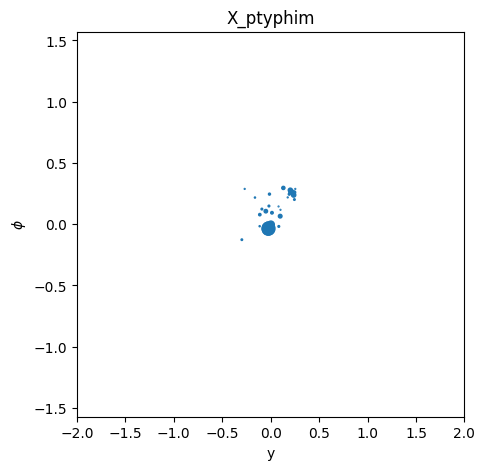

In [3]:
jet_index = 3
plt.figure(figsize=(5,5))
plt.scatter(all_events[jet_index,:,1], all_events[jet_index,:,2], s=all_events[jet_index,:,0])
plt.xlabel("y")
plt.ylabel(r"$\phi$")
plt.xlim(-2,2)
plt.ylim(-np.pi/2, np.pi/2)
plt.title("X_ptyphim")
plt.show()

In [4]:
# Definition of User Info: pdg_id


class ParticleInfo(object):
    """illustrative class for use in assigning pythonic user information
    to a PseudoJet.
    """

    def __init__(self, particle_index, pdg_id=0):
        self.particle_index = particle_index
        self.pdg_id = pdg_id

    def set_pdg_id(self, pdg_id):
        self.pdg_id = pdg_id

    def __str__(self):
        return "particle_index={1}, pdg_id={2}".format(self.particle_index, self.pdg_id)


# Define the way to read the input file
jet_index = 0

def read_jet(file_or_filename):
    """
    Routine that can take either an existing opened file object, or a
    filename (which it will open itself) and then reads an event from that
    file. An event is deemed to end when the file comes to an end or when
    the reader encounters the string "#END EVENT".

    The event is converted to a python list of PseudoJets
    """

    # open the file if necessary
    if isinstance(file_or_filename, str):
        f = open(file_or_filename, "r")
    else:
        f = file_or_filename

    # create an empty list
    jet = []
    particle_index = 0
    while True:
        line = f.readline()
        # exit if the file has come to an end
        if not line:
            break
        # or if we reach the string "#END EVENT"
        if line[0:4] == "#END":
            break

        # ignore comment lines or empty lines
        elif line[0] == "#" or len(line) <= 1:
            continue

        # assume we have a good line and split it into px, py, pz, E
        p = line.split()
        pj = fj.PseudoJet(float(p[0]), float(p[1]), float(p[2]), float(p[3]))

        # then create its user info
        info = ParticleInfo(particle_index)
        # optionally with a pdg_id (if it was in the file)
        if len(p) > 4:
            info.set_pdg_id(int(p[4]))

        # finally assign the user info and append the particle the event
        pj.set_python_info(info)
        jet.append(pj)

        # don't forget to increment it
        particle_index += 1

    global jet_index
    jet_index += 1
    return jet

In [5]:
# Input & Output files (please change the directory according to your actual file path)
inputfile = 'all_jets_p4s.dat'
outputfile = 'all_jets_9_subjets_p4s.npz'
infile = open(inputfile, 'r')

In [6]:
# jet definition
R = 0.8
#jet_def = fj.JetDefinition(fj.antikt_algorithm, R)
jet_def = fj.JetDefinition(fj.kt_algorithm, R)
#jet_def = fj.JetDefinition(fj.cambridge_algorithm, R)
print("jet definition is:", jet_def)

jet definition is: Longitudinally invariant kt algorithm with R = 0.8 and E scheme recombination


In [7]:
# selector
#selector = fj.SelectorPtRange(500.0, 550.0) & fj.SelectorAbsRapMax(1.7)
selector = fj.SelectorPtMin(0) # no additional selector is needed since the input is already classified to jets in FJ (using anti-kt algorithm)
print("jet selector is:", selector)

jet selector is: pt >= 0


In [8]:
# Define the output arrays
jets_subjets_ptyphim = []
jets_subjets_epxpypz = []

In [9]:
# Get the event
ijet = 0
nsubjet = 9 # desired number of subjets in each jet
failed_index = []
while True: # for each jet
    jet = read_jet(infile)
    # keep track of the progress
    if ijet % 1000 == 0:
        print("Processing Jet: ", ijet)
        
    if (len(jet) == 0): break
    cs = fj.ClusterSequence(jet, jet_def)
    #subjets = selector(cs.inclusive_jets())
    subjets = selector(cs.exclusive_jets_up_to(nsubjet)) # use exclusive_jets_up_to instead of exclusive_jets to avoid error
    subjets = fj.sorted_by_pt(subjets) # hardest subjet first
    subjets_axis_ptyphim = []
    subjets_axis_epxpypz = []
    
    if len(subjets)<nsubjet: # discard the jets with <nsubjet subjets
        print(ijet, len(subjets))
        failed_index.append(ijet)
    else: # only keep the jets with nsubjet subjets
        for isubjet in range(len(subjets)):
            # keep all subjets (which should be nsubjet)
            subjet = subjets[isubjet]            
            subjets_axis_ptyphim.append([subjet.pt(), subjet.rap(), subjet.phi_std(), 0]) # axis for all subjets in one jet in [pt, y, phi, m=0] order
            e_subjet = np.sqrt(subjet.px()**2 + subjet.py()**2 + subjet.pz()**2) # set subjet to be massless with e = sqrt(px^2 + py^2 + pz^2)
            subjets_axis_epxpypz.append([e_subjet, subjet.px(), subjet.py(), subjet.pz()]) # axis for all subjets in one jet in [e, px, py, pz] order
        subjets_axis_ptyphim = np.array(subjets_axis_ptyphim)
        
        if 0 in subjets_axis_ptyphim[:,0]: # discard the jet if a subjet has pt=0
            print(ijet, len(subjets))
            failed_index.append(ijet)
        else:
            jets_subjets_ptyphim.append(subjets_axis_ptyphim) # axis for all subjets in all jets
            jets_subjets_epxpypz.append(subjets_axis_epxpypz) # axis for all subjets in all jets    
    ijet += 1
    
jets_subjets_ptyphim = np.array(jets_subjets_ptyphim)
jets_subjets_epxpypz = np.array(jets_subjets_epxpypz)
jets_subjets_ptyphim.shape, jets_subjets_epxpypz.shape, len(failed_index)

Processing Jet:  0
#--------------------------------------------------------------------------
#                         FastJet release 3.5.1
#                 M. Cacciari, G.P. Salam and G. Soyez                  
#     A software package for jet finding and analysis at colliders      
#                           https://fastjet.fr                           
#	                                                                      
# Please cite EPJC72(2012)1896 [arXiv:1111.6097] if you use this package
# for scientific work and optionally PLB641(2006)57 [hep-ph/0512210].   
#                                                                       
# FastJet is provided without warranty under the GNU GPL v2 or higher.  
# It uses T. Chan's closest pair algorithm, S. Fortune's Voronoi code,
# CGAL and 3rd party plugin jet algorithms. See COPYING file for details.
#--------------------------------------------------------------------------
Processing Jet:  1000
Processing Jet:  2000
Process

Processing Jet:  13000
Processing Jet:  14000
Processing Jet:  15000
Processing Jet:  16000
Processing Jet:  17000
Processing Jet:  18000
Processing Jet:  19000
Processing Jet:  20000
Processing Jet:  21000
Processing Jet:  22000
Processing Jet:  23000
Processing Jet:  24000
Processing Jet:  25000
Processing Jet:  26000
Processing Jet:  27000
Processing Jet:  28000
Processing Jet:  29000
Processing Jet:  30000
Processing Jet:  31000
Processing Jet:  32000


((32000, 9, 4), (32000, 9, 4), 0)

In [10]:
X_ptyphim = []
X_epxpypz = []
for i in range(len(jets_subjets_ptyphim)):
    X_ptyphim.append(jets_subjets_ptyphim[i])
    X_epxpypz.append(jets_subjets_epxpypz[i])
X_ptyphim = np.array(X_ptyphim)
X_epxpypz = np.array(X_epxpypz)

X_ptyphim.shape, X_epxpypz.shape

((32000, 9, 4), (32000, 9, 4))

In [11]:
X_ptyphim[:, :, 2] = (X_ptyphim[:, :, 2] + 2*np.pi) % (np.pi*2)

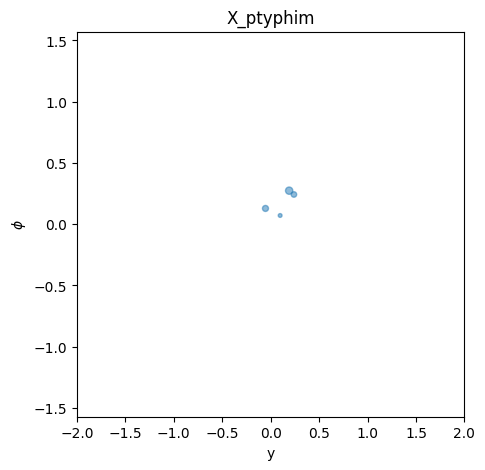

In [12]:
jet_index = 3
plt.figure(figsize=(5,5))
plt.scatter(X_ptyphim[jet_index,:,1], X_ptyphim[jet_index,:,2], s=X_ptyphim[jet_index,:,0], alpha=0.5)
plt.xlabel("y")
plt.ylabel(r"$\phi$")
plt.xlim(-2,2)
plt.ylim(-np.pi/2, np.pi/2)
plt.title("X_ptyphim")
plt.show()

In [13]:
print(X_ptyphim[jet_index])

[[ 1.38221938e+02 -2.16223623e-02  6.24713338e+00  0.00000000e+00]
 [ 1.36108853e+02 -2.04566339e-02  6.25424793e+00  0.00000000e+00]
 [ 1.07895810e+02 -2.39432716e-02  6.24239681e+00  0.00000000e+00]
 [ 3.23195653e+01  5.66241040e-03  6.28006567e+00  0.00000000e+00]
 [ 2.77551991e+01  1.90992643e-01  2.73799060e-01  0.00000000e+00]
 [ 2.25252723e+01 -6.71631960e-02  6.24592995e+00  0.00000000e+00]
 [ 1.87781114e+01 -5.34478926e-02  1.28757899e-01  0.00000000e+00]
 [ 1.58512327e+01  2.40085530e-01  2.42672411e-01  0.00000000e+00]
 [ 7.51391509e+00  9.78728886e-02  7.12906152e-02  0.00000000e+00]]


In [14]:
jets_axis_epxpypz = []
for i in range(X_epxpypz.shape[0]):
    jet_axis_epxpypz = [np.sum(X_epxpypz[i,:,0]), np.sum(X_epxpypz[i,:,1]), np.sum(X_epxpypz[i,:,2]), np.sum(X_epxpypz[i,:,3])]
    jets_axis_epxpypz.append(jet_axis_epxpypz)
jets_axis_epxpypz = np.array(jets_axis_epxpypz)
jets_axis_epxpypz.shape

(32000, 4)

In [15]:
# Rotate X_epxpypz (used for PSCoord computation) according to Andrew's notes for collinear jets
X_transformed_epxpypz = []
jets_axis_transformed_epxpypz = []
E_list = []
m_list = []
p_minus_list = []
p_plus_list = []

for i in range(X_epxpypz.shape[0]):
    jet_epxpypz = X_epxpypz[i]
    E = jets_axis_epxpypz[i,0] # jet energy
    px_jet = jets_axis_epxpypz[i,1]
    py_jet = jets_axis_epxpypz[i,2]
    pz_jet = jets_axis_epxpypz[i,3]
    m = np.sqrt(E**2 - px_jet**2 - py_jet**2 - pz_jet**2) # jet mass, after rotation should be np.sqrt(E**2 - pz**2)
    
    # compute the rotation matrix from jet axes   
    p_jet = np.sqrt(px_jet**2 + py_jet**2 + pz_jet**2)
    cos_theta = pz_jet / p_jet
    sin_theta = np.sqrt(1-cos_theta**2)
    ux = py_jet / np.sqrt(px_jet**2 + py_jet**2)
    uy = -px_jet / np.sqrt(px_jet**2 + py_jet**2)
    # uz = 0
    
    # rotate the jet axis, should be [E, 0, 0, p_jet]
    px_jet_new = (cos_theta+ux**2*(1-cos_theta))*px_jet + ux*uy*(1-cos_theta)*py_jet + uy*sin_theta*pz_jet
    py_jet_new = ux*uy*(1-cos_theta)*px_jet + (cos_theta+uy**2*(1-cos_theta))*py_jet - ux*sin_theta*pz_jet
    pz_jet_new = - uy*sin_theta*px_jet + ux*sin_theta*py_jet + cos_theta*pz_jet
    jets_axis_transformed_epxpypz.append([E, px_jet_new, py_jet_new, pz_jet_new])
    
    # rotate subjets accordingly
    jet_transformed_epxpypz = []
    for j in range(X_epxpypz.shape[1]):
        px = X_epxpypz[i,j,1]
        py = X_epxpypz[i,j,2]
        pz = X_epxpypz[i,j,3]
        px_new = (cos_theta+ux**2*(1-cos_theta))*px + ux*uy*(1-cos_theta)*py + uy*sin_theta*pz
        py_new = ux*uy*(1-cos_theta)*px + (cos_theta+uy**2*(1-cos_theta))*py - ux*sin_theta*pz
        pz_new = - uy*sin_theta*px + ux*sin_theta*py + cos_theta*pz
        jet_transformed_epxpypz.append([X_epxpypz[i,j,0], px_new, py_new, pz_new])
    X_transformed_epxpypz.append(jet_transformed_epxpypz)
    
    p_minus = E + pz_jet_new # should be 2 * E in the collinear limit
    p_plus = E - pz_jet_new # should be m**2 / (2 * E) in the collinear limit
    
    E_list.append(E)
    m_list.append(m)
    p_minus_list.append(p_minus)
    p_plus_list.append(p_plus)

X_transformed_epxpypz = np.array(X_transformed_epxpypz)
jets_axis_transformed_epxpypz = np.array(jets_axis_transformed_epxpypz)
E_list = np.array(E_list)
m_list = np.array(m_list)
p_minus_list = np.array(p_minus_list)
p_plus_list = np.array(p_plus_list)
X_transformed_epxpypz.shape, jets_axis_transformed_epxpypz.shape, E_list.shape, m_list.shape, p_minus_list.shape, p_plus_list.shape

((32000, 9, 4), (32000, 4), (32000,), (32000,), (32000,), (32000,))

In [16]:
# Output the npz file
np.savez(outputfile, X_ptyphim=X_ptyphim, X_epxpypz=X_epxpypz, 
         X_transformed_epxpypz=X_transformed_epxpypz, E_list=E_list, m_list=m_list, p_minus_list=p_minus_list, p_plus_list=p_plus_list)

In [17]:
X_transformed_epxpypz

array([[[ 3.51639043e+02, -9.96153612e-01,  1.43829564e-01,
          3.51637602e+02],
        [ 8.15886884e+01, -3.46573536e-01,  3.41583454e-01,
          8.15872372e+01],
        [ 3.25290980e+01,  9.29465813e-02,  3.17252972e-01,
          3.25274181e+01],
        ...,
        [ 3.50270857e+00, -1.22925788e-01, -6.93553894e-01,
          3.43115718e+00],
        [ 1.72421569e+00, -3.10650082e-01,  7.88550601e-02,
          1.69416592e+00],
        [ 1.62024261e+00, -6.08968782e-02, -1.69285950e-01,
          1.61022358e+00]],

       [[ 3.59140228e+02,  2.96877226e-01, -7.63557901e-01,
          3.59139294e+02],
        [ 7.13349157e+01,  8.55426206e-01,  1.09866459e+00,
          7.13213248e+01],
        [ 7.10126293e+01, -1.14286699e-01, -1.21594395e-01,
          7.10124332e+01],
        ...,
        [ 5.34999521e+00,  3.45427899e-01,  4.43804112e-01,
          5.32035396e+00],
        [ 1.77023532e+00, -5.82726619e-01,  4.37350509e-02,
          1.67100270e+00],
        [ 1.335